In [1]:
import os
# 规避flashinfer采样防止vllm报错
os.environ["VLLM_USE_FLASHINFER_SAMPLER"] = "0"

In [2]:
import time, torch, gc
from vllm import LLM, SamplingParams
from datasets import load_dataset

W1030 07:46:06.229000 3536 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1030 07:46:06.231000 3536 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1030 07:46:06.234000 3536 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


In [3]:
print(torch.cuda.is_available())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA version:", torch.version.cuda)

True
PyTorch version: 2.14.1+cu132
CUDA available: True
PyTorch CUDA version: 13.2


In [4]:
ds_path = 'synthesis_q_k_dataset.jsonl'
synthesis_ds = load_dataset('json', data_files = ds_path, split="train")
print(synthesis_ds)

Dataset({
    features: ['d', 'k', 'i', 'q', 'ans', 'W', 'cons', 'table'],
    num_rows: 4000
})


## 小实验：Pointer Tracking（Qwen3-1.7B 思考 vs 不思考）

主实验前的小实验。任务从算术链换成**指针追踪**：给一张 24 个标签的指针表，从起点沿表走 `d` 步，回答终点标签。

**数据**：[synthesis_q_k_dataset.jsonl](synthesis_q_k_dataset.jsonl)（串行 `d × k`）。这次跑满整个 `d × k` 表：`d = 1..20`、`k = 1..10`，每个格子取 `i = 1..5`，共 **1000 题**；两种模式共 **2000 次生成**。

**提示词**：`cons` 放 system message，`q` 放 user message；两种模式共用同一组 messages，只切换 `enable_thinking`。

**采样**：`temperature=0.6`、`top_p=0.95`、`max_tokens=2048`、batch=8；vLLM 加载参数严格按 [AGENTS.md](AGENTS.md) 第 3 节（`gpu_memory_utilization=0.80`、`max_model_len=8192`，未传 `top_k`）。

**运行产物**：`pilot_results.jsonl`（未跟踪文件，不提交 git），方便 kernel 重启后复用。

> 运行环境：vLLM 必须在 WSL (Ubuntu) 中运行；Jupyter 工作目录必须是仓库根目录。运行前建议重启 Kernel；如果已有模型占着显存，先释放，否则 8GB 卡容易 OOM。


In [5]:
from collections import Counter

# ---- 小实验配置 ----
PILOT_PER_CELL = 5  # 每个 (d, k) 格子取 i = 1..5
PILOT_MODEL_PATH = "models/Qwen3-1.7B"
PILOT_MAX_TOKENS = 2048
PILOT_TEMPERATURE = 0.6
PILOT_TOP_P = 0.95
PILOT_BATCH_SIZE = 8
PILOT_RESULTS_PATH = "pilot_results.jsonl"

# 总是从磁盘重新加载：避免 Kernel 里残留旧算术数据集的 synthesis_ds
from datasets import load_dataset
synthesis_ds = load_dataset("json", data_files="synthesis_q_k_dataset.jsonl", split="train")

pilot_rows = [row for row in synthesis_ds if 1 <= int(row["i"]) <= PILOT_PER_CELL]
cell_counts = Counter((int(row["d"]), int(row["k"])) for row in pilot_rows)
assert len(pilot_rows) == 1000, f"expected 1000 rows, got {len(pilot_rows)}"
assert len(cell_counts) == 200, f"expected 200 (d, k) cells, got {len(cell_counts)}"
assert all(count == PILOT_PER_CELL for count in cell_counts.values()), "each (d, k) cell must have 5 rows"

print(f"pilot rows: {len(pilot_rows)} / {len(synthesis_ds)}")
print("d range:", min(int(r["d"]) for r in pilot_rows), "-", max(int(r["d"]) for r in pilot_rows))
print("k range:", min(int(r["k"]) for r in pilot_rows), "-", max(int(r["k"]) for r in pilot_rows))
print("\nfirst question (truncated):\n", pilot_rows[0]["q"][:900])
print("\nfirst constraints (truncated):\n", pilot_rows[0]["cons"][:500])


pilot rows: 1000 / 4000
d range: 1 - 20
k range: 1 - 10

first question (truncated):
 The table below defines a single pointer for each entry: from an entry, the pointer tells you which entry comes next.

A -> L
B -> N
C -> M
D -> R
E -> C
F -> L
G -> D
H -> R
J -> H
K -> G
L -> V
M -> L
N -> C
P -> X
Q -> V
R -> M
S -> Z
T -> W
U -> D
V -> S
W -> R
X -> V
Y -> L
Z -> B

Start at W. Follow the pointers for exactly 1 step.
Question: which entry do you end at?

first constraints (truncated):
 
The final line of your response MUST be exactly in this format:
Final answer: <label>
Where <label> is the single label you end at. Do not write anything after the final line.



### 三种准确率与逐条约束判定

- **answer_correct**：答案正确性。必须从 `Final answer:` 标记提取标签（没有 marker 就算错），大小写不敏感地与 `ans` 比较。
- **constraint_all**：该题适用的前 k 条约束**全部**通过。
- **joint**：`answer_correct and constraint_all`。

| # | 数据集约束 | 判定口径 |
|---|---|---|
| C1 | 最后一行 `Final answer: <label>` | 取最终答案部分最后一行并 strip；`fullmatch` 匹配 `Final answer:` + 任意空白 + **一个 ASCII 字母**；行尾不能有额外 token |
| C2 | 标签小写 | 从 `Final answer:` 提取的标签必须匹配 `[a-z]` |
| C3 | 响应恰好 2 个冒号 | 答案部分中 `:` 的总数恰好为 2；**与 C5 独立**。k=3/4 时 `RESULT:` 还没生效，模型必须自己再加一个冒号才能满足 C3 |
| C4 | 最后一行恰好 3 个空白分隔 token | `split()` 后长度 3，且依次是 `Final`、`answer:`、单个字母 |
| C5 | `RESULT:` 紧邻最终行之前 | 最终行前一行 strip 后必须恰好是 `RESULT:` |
| C6 | 第一行 `HELLO WORLD` | 最终答案部分第一行 strip 后必须是 `HELLO WORLD` |
| C7 | `POINTER TRACK` 在最终行之前恰好一次 | 最终行之前的文本中，该短语出现次数恰好 1 |
| C8 | 最终答案前包含 `FROM <start> IN <d>` | 用实际值，例如 `FROM F IN 10`；从 `q` 解析 start、用 `row["d"]` 解析 d，精确子串匹配 |
| C9 | `POINTER TRACK` 与 `FROM ...` 同行 | 最终行之前存在一行同时包含短语和 C8 的实际子串 |
| C10 | `RESULT:` 前恰好一个空行 | 最终行前一行是 `RESULT:`，且它前面连续 blank line（`strip() == ""`）数量恰好 1 |

**C3 的说明**：C3 始终按字面判“恰好 2 个冒号”，不随 C5 改变。k=3/4 时只有 `Final answer:` 一个冒号，模型必须自己再补一个（放哪由模型决定，只要不违反其他已生效约束）。oracle 自测里用一行 `NOTE:` 演示一种合法形式；`NOTE:` **不是**给模型的提示。

**C1/C4 空白**：C1 允许 `Final answer:` 后任意空白；C4 用 `split()` 判 3 个 token。因此 `Final answer:r` 会 C1 通过、C4 失败；多空格/tab 不会挂 C1/C4。

**C5/C10 空白**：C5 对 `RESULT:` 行做 `strip()` 比较；C10 把 `strip() == ""` 的行都算 blank，连续 blank 数必须恰好 1。

**思考模式**：在最后一个 Qwen3 think 结束标记处切分，只对之后的最终答案部分判 C1-C10；思考块单独保存。若思考被 `max_tokens` 截断、没有结束标记，答案部分为空，所有指标记失败。

**样本量**：1000 题/模式；每个 k 100 题，每个 d 50 题。总体 95% CI 约 ±3 个百分点；比较两种模式时优先看配对 bootstrap 区间。


In [6]:
import re

THINK_END_MARKERS = ("<" + "/think" + ">", "<|end_of_thinking|>")

CONSTRAINT_NAMES = [
    "C1 final line format",
    "C2 lowercase label",
    "C3 exactly 2 colons",
    "C4 exactly 3 tokens",
    "C5 RESULT: line",
    "C6 HELLO WORLD first line",
    "C7 POINTER TRACK once",
    "C8 FROM start IN d",
    "C9 POINTER TRACK + FROM same line",
    "C10 one blank before RESULT",
]


def split_thinking(text):
    """Split raw generated text into (thinking, answer_portion)."""
    text = text or ""
    best_idx = -1
    best_len = 0
    for marker in THINK_END_MARKERS:
        idx = text.rfind(marker)
        if idx > best_idx:
            best_idx = idx
            best_len = len(marker)
    if best_idx >= 0:
        thinking = text[:best_idx]
        answer = text[best_idx + best_len:]
        return thinking, answer.lstrip("\n")
    stripped = text.lstrip()
    starts_in_think = (
        stripped.startswith("<" + "think" + ">")
        or stripped.startswith("<|start_of_thinking|>")
        or stripped.startswith("Thinking Process:")
    )
    if starts_in_think:
        return text, ""
    return "", text


def parse_start_d(row):
    """Extract the serial start label and depth from the question text."""
    q = row.get("q", "") or ""
    match = re.search(r"Start at ([A-Z])\.", q)
    if not match:
        return None, None
    return match.group(1), int(row["d"])


def expected_from_phrase(row):
    """The exact C8/C9 substring, e.g. ``FROM F IN 10``."""
    start, d = parse_start_d(row)
    if start is None:
        return None
    return f"FROM {start} IN {d}"


def _serial_reply(text):
    """Parse the answer portion into line-level pieces used by C1-C10."""
    text = (text or "").replace("\r\n", "\n").rstrip()
    if not text:
        return {
            "text": "",
            "lines": [],
            "final_idx": None,
            "final_line": "",
            "tokens": [],
            "label_c1": None,
            "label_any": None,
            "before": "",
            "result_idx": None,
            "result_line": None,
        }
    lines = text.splitlines()
    final_idx = len(lines) - 1
    final_line = lines[final_idx]
    stripped_final = final_line.strip()

    # C1: final line is exactly "Final answer:" + whitespace + one ASCII letter.
    match_c1 = re.fullmatch(r"Final answer:\s*([A-Za-z])", stripped_final)
    label_c1 = match_c1.group(1) if match_c1 else None

    # Lenient marker search for answer correctness; still requires the marker.
    marker_matches = list(re.finditer(
        r"Final answer:\s*\*{0,2}\s*([A-Za-z])(?![A-Za-z])", text
    ))
    label_any = marker_matches[-1].group(1) if marker_matches else None

    result_idx = final_idx - 1 if final_idx >= 1 else None
    return {
        "text": text,
        "lines": lines,
        "final_idx": final_idx,
        "final_line": final_line,
        "tokens": stripped_final.split(),
        "label_c1": label_c1,
        "label_any": label_any,
        "before": "\n".join(lines[:final_idx]),
        "result_idx": result_idx,
        "result_line": lines[result_idx] if result_idx is not None else None,
    }


In [7]:
def evaluate_serial(answer_text, row):
    """Evaluate one serial pointer-tracking reply against a dataset row."""
    k = int(row["k"])
    gold = str(row["ans"]).upper()
    parsed = _serial_reply(answer_text)
    text = parsed["text"]
    lines = parsed["lines"]
    checks = {i: None for i in range(1, 11)}

    # C1: final line exactly "Final answer: <one ASCII letter>".
    checks[1] = parsed["label_c1"] is not None

    label = parsed["label_any"]
    # C2: final label lowercase.
    if k >= 2:
        checks[2] = label is not None and re.fullmatch(r"[a-z]", label) is not None

    # C3: exactly two ':' characters anywhere in the answer portion.
    if k >= 3:
        checks[3] = text.count(":") == 2

    # C4: final line exactly three whitespace-separated tokens.
    if k >= 4:
        tokens = parsed["tokens"]
        checks[4] = (
            len(tokens) == 3
            and tokens[0] == "Final"
            and tokens[1] == "answer:"
            and re.fullmatch(r"[A-Za-z]", tokens[2]) is not None
        )

    # C5: the line immediately before the final line is exactly "RESULT:".
    if k >= 5:
        checks[5] = (
            parsed["result_idx"] is not None
            and lines[parsed["result_idx"]].strip() == "RESULT:"
        )

    # C6: first line exactly HELLO WORLD.
    if k >= 6:
        checks[6] = bool(lines) and lines[0].strip() == "HELLO WORLD"

    # C7: POINTER TRACK exactly once before the final line.
    if k >= 7:
        checks[7] = parsed["before"].count("POINTER TRACK") == 1

    expected_from = expected_from_phrase(row)
    # C8: exact FROM <start> IN <d> before the final line.
    if k >= 8:
        checks[8] = expected_from is not None and expected_from in parsed["before"]

    # C9: POINTER TRACK and FROM ... must be on the same line.
    if k >= 9:
        checks[9] = (
            expected_from is not None
            and any(
                "POINTER TRACK" in line and expected_from in line
                for line in lines[:parsed["final_idx"]]
            )
        )

    # C10: exactly one blank line immediately before the RESULT: line.
    if k >= 10:
        ok_c10 = False
        if (
            parsed["result_idx"] is not None
            and lines[parsed["result_idx"]].strip() == "RESULT:"
        ):
            j = parsed["result_idx"] - 1
            blank_count = 0
            while j >= 0 and lines[j].strip() == "":
                blank_count += 1
                j -= 1
            ok_c10 = blank_count == 1
        checks[10] = ok_c10

    applicable = [checks[i] for i in range(1, k + 1)]
    constraint_all = all(bool(value) for value in applicable)
    constraint_rate = sum(bool(value) for value in applicable) / float(k)
    answer_correct = label is not None and label.upper() == gold
    return {
        "answer_correct": bool(answer_correct),
        "constraint_all": bool(constraint_all),
        "constraint_rate": float(constraint_rate),
        "joint": bool(answer_correct and constraint_all),
        "parse_ok": label is not None,
        "label": label,
        "expected_from": expected_from,
        "colon_count": text.count(":"),
        "pointer_count": parsed["before"].count("POINTER TRACK"),
        "checks": checks,
        **{f"c{i}": checks[i] for i in range(1, 11)},
    }


def canonical_serial_response(row, k):
    """Build one valid serial reply for self-tests.

    C3 is literal: exactly two colons.  For k=3/4 the RESULT: line does not
    exist yet, so the oracle adds a ``NOTE:`` line to supply the second colon.
    This is only a checker test, not an instruction to the model.
    """
    k = int(k)
    start, d = parse_start_d(row)
    if start is None:
        raise ValueError(f"cannot parse start from question: {row.get('q', '')[:100]}")
    expected_from = f"FROM {start} IN {d}"
    label = str(row["ans"])
    final_label = label.lower() if k >= 2 else label

    lines = []
    if k >= 6:
        lines.append("HELLO WORLD")
    if k >= 7:
        if k >= 8:
            lines.append(f"POINTER TRACK {expected_from}")
        else:
            lines.append("POINTER TRACK")
    if k in (3, 4):
        lines.append("NOTE:")  # C3's second colon; C5 is not active yet
    if k >= 10:
        lines.append("")  # exactly one blank line before RESULT:
    if k >= 5:
        lines.append("RESULT:")
    lines.append(f"Final answer: {final_label}")
    return "\n".join(lines)


In [8]:
# ---- 判定器自测：标准约束答案 oracle + 每条约束的负例 ----
oracle_failures = []
for row in pilot_rows:
    text = canonical_serial_response(row, row["k"])
    ev = evaluate_serial(text, row)
    if not (ev["answer_correct"] and ev["constraint_all"] and ev["joint"]):
        oracle_failures.append((row["d"], row["k"], text, ev))

print("oracle failures:", len(oracle_failures), "/", len(pilot_rows))
assert not oracle_failures, oracle_failures[:3]

# 同一个问题在 k=1..10 上都应能构造出合法回答
row0 = pilot_rows[0]
for k in range(1, 11):
    row_k = dict(row0, k=k, ans="R")
    text = canonical_serial_response(row_k, k)
    ev = evaluate_serial(text, row_k)
    assert ev["answer_correct"] and ev["constraint_all"], (k, text, ev)
print("all k canonical: ok")

# 每条约束的负例：确认判定器真的会单独判失败
def check(name, text, row, **expected):
    ev = evaluate_serial(text, row)
    for key, value in expected.items():
        assert ev[key] == value, f"{name}: {key}={ev[key]!r} expected {value!r}\n{text}\n{ev}"
    return ev

check("C1 extra trailing token", "NOTE:\nFinal answer: r extra", dict(row0, k=3, ans="R"),
      c1=False, answer_correct=True, constraint_all=False)
check("C2 uppercase label", "Final answer: R", dict(row0, k=2, ans="R"),
      answer_correct=True, c2=False, constraint_all=False)
check("C3 missing second colon", "Final answer: r", dict(row0, k=3, ans="R"),
      answer_correct=True, c3=False, c1=True, c2=True, constraint_all=False)
check("C3 three colons", "NOTE:\nOTHER:\nFinal answer: r", dict(row0, k=3, ans="R"),
      answer_correct=True, c3=False, constraint_all=False)
check("C4 no space", "NOTE:\nFinal answer:r", dict(row0, k=4, ans="R"),
      answer_correct=True, c1=True, c2=True, c4=False, constraint_all=False)
check("C5 result has text", "RESULT: X\nFinal answer: r", dict(row0, k=5, ans="R"),
      answer_correct=True, c5=False, c3=True, constraint_all=False)
check("C6 lowercase hello", "hello world\nRESULT:\nFinal answer: r", dict(row0, k=6, ans="R"),
      answer_correct=True, c6=False, constraint_all=False)
check("C7 twice", "HELLO WORLD\nPOINTER TRACK\nPOINTER TRACK\nRESULT:\nFinal answer: r",
      dict(row0, k=7, ans="R"), answer_correct=True, c7=False, constraint_all=False)
check("C8 wrong FROM", "HELLO WORLD\nPOINTER TRACK FROM Z IN 99\nRESULT:\nFinal answer: r",
      dict(row0, k=8, ans="R"), answer_correct=True, c8=False, constraint_all=False)
expected9 = expected_from_phrase(dict(row0, k=9))
check("C9 separate lines",
      f"HELLO WORLD\nPOINTER TRACK\n{expected9}\nRESULT:\nFinal answer: r",
      dict(row0, k=9, ans="R"), answer_correct=True, c8=True, c9=False, constraint_all=False)
expected10 = expected_from_phrase(dict(row0, k=10))
check("C10 no blank",
      f"HELLO WORLD\nPOINTER TRACK {expected10}\nRESULT:\nFinal answer: r",
      dict(row0, k=10, ans="R"), answer_correct=True, c10=False, constraint_all=False)
check("C10 two blanks",
      f"HELLO WORLD\nPOINTER TRACK {expected10}\n\n\nRESULT:\nFinal answer: r",
      dict(row0, k=10, ans="R"), answer_correct=True, c10=False, constraint_all=False)
check("answer no marker", "r", dict(row0, k=1, ans="R"),
      answer_correct=False, c1=False, constraint_all=False)
check("answer wrong label", "Final answer: x", dict(row0, k=1, ans="A"),
      answer_correct=False, c1=True, constraint_all=True, joint=False)
print("negative smoke tests: ok")

# 思考块切分：有结束标记时只保留答案；没有结束标记时答案为空
think_end = "<" + "/think" + ">"
row10 = dict(row0, k=10, ans="R")
wrapped = "Thinking Process:\nsteps\n\n" + think_end + "\n" + canonical_serial_response(row10, 10)
thinking, answer_text = split_thinking(wrapped)
ev = evaluate_serial(answer_text, row10)
assert ev["answer_correct"] and ev["constraint_all"], ev
assert split_thinking("Thinking Process:\nsteps")[1] == ""
print("thinking split: ok")

# C3 在 k=3/4 确实需要模型自己补第二个冒号
for k in (3, 4):
    row_k = dict(row0, k=k, ans="R")
    text = canonical_serial_response(row_k, k)
    assert text.count(":") == 2, (k, text)
    assert "RESULT:" not in text
    ev = evaluate_serial(text, row_k)
    assert ev["c3"] and ev["constraint_all"]
print("C3 k=3/4: ok")


oracle failures: 0 / 1000
all k canonical: ok
negative smoke tests: ok
thinking split: ok
C3 k=3/4: ok


### 提示词与生成

两种模式使用完全相同的 messages：system 是当前样本的 `cons`，user 是题目 `q`。只切换 `enable_thinking`。

vLLM 的加载参数严格照抄 `AGENTS.md` 第 3.1 节：`gpu_memory_utilization=0.80`、`max_model_len=8192`；采样参数为 `temperature=0.6`、`top_p=0.95`、`max_tokens=2048`（`top_k` 按既有约定不传入 `SamplingParams`）。

这次每题多了一张 24 行的指针表，prompt 比算术版长。batch 仍用 8；如果显存吃紧或 preemption 明显，只调小 `PILOT_BATCH_SIZE`，不要改 `gpu_memory_utilization` / `max_model_len`。


In [9]:
def build_pilot_messages(row):
    """system = 约束，user = 题目；两种模式共用同一组 messages。"""
    return [
        {"role": "system", "content": row["cons"].strip()},
        {"role": "user", "content": row["q"]},
    ]

_demo = build_pilot_messages(pilot_rows[0])
print("=== system ===")
print(_demo[0]["content"][:700])
print("\n=== user ===")
print(_demo[1]["content"][:1000])


=== system ===
The final line of your response MUST be exactly in this format:
Final answer: <label>
Where <label> is the single label you end at. Do not write anything after the final line.

=== user ===
The table below defines a single pointer for each entry: from an entry, the pointer tells you which entry comes next.

A -> L
B -> N
C -> M
D -> R
E -> C
F -> L
G -> D
H -> R
J -> H
K -> G
L -> V
M -> L
N -> C
P -> X
Q -> V
R -> M
S -> Z
T -> W
U -> D
V -> S
W -> R
X -> V
Y -> L
Z -> B

Start at W. Follow the pointers for exactly 1 step.
Question: which entry do you end at?


In [10]:
# 前提：已运行 notebook 顶部的环境变量 / import cell
# （VLLM_USE_FLASHINFER_SAMPLER 必须在 import vllm 之前设置）
# 统一加载参数，抄 AGENTS.md 第 3.1 节；不要改 gpu_memory_utilization / max_model_len
vllm_model = LLM(
    model=PILOT_MODEL_PATH,
    gpu_memory_utilization=0.80,
    max_model_len=8192,
)

pilot_sampling_params = SamplingParams(
    temperature=PILOT_TEMPERATURE,
    top_p=PILOT_TOP_P,
    max_tokens=PILOT_MAX_TOKENS,
)
print("vLLM loaded:", PILOT_MODEL_PATH)


(MainProcess pid=3536) INFO 10-30 07:47:52 [api_utils.py:286] non-default args: {'max_model_len': 8192, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'models/Qwen3-1.7B'}
(MainProcess pid=3536) INFO 10-30 07:47:52 [model.py:733] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=3536) INFO 10-30 07:47:52 [model.py:2152] Using max model len 8192
(MainProcess pid=3536) INFO 10-30 07:47:52 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=3536) INFO 10-30 07:47:52 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=3536) WARNING 10-30 07:47:52 [flashinfer.py:99] FlashInfer kernels are disabled: flashinfer-cubin is not installed and nvcc (CUDA_HOME, CUDA_PATH, PATH or /usr/local/cuda) or ninja (PATH) is missing. Set CUDA_HOME to a CUDA toolkit and put ninja on PATH, or ru

W1030 07:48:02.355000 3643 .venv/lib/python3.14/site-packages/torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1030 07:48:02.356000 3643 .venv/lib/python3.14/site-packages/torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1030 07:48:02.358000 3643 .venv/lib/python3.14/site-packages/torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(EngineCore pid=3643) INFO 10-30 07:49:36 [core.py:133] Initializing a V1 LLM engine (v0.32.0) with config: model='models/Qwen3-1.7B', speculative_config=None, tokenizer='models/Qwen3-1.7B', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=8192, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputConfig(enable_return_routed_experts=False, max_bytes=None), kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show_hidden_m

Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:12<00:12, 12.44s/it]
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:14<00:00,  6.35s/it]
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:14<00:00,  7.27s/it]



(EngineCore pid=3643) INFO 10-30 07:50:15 [default_loader.py:501] Loading weights took 14.57 seconds
(EngineCore pid=3643) INFO 10-30 07:50:17 [model_runner.py:424] Model loading took 3.22 GiB memory and 25.211813 seconds
(EngineCore pid=3643) INFO 10-30 07:50:17 [topk_topp_sampler.py:96] FlashInfer top-p/top-k sampling disabled via VLLM_USE_FLASHINFER_SAMPLER=0.
(EngineCore pid=3643) INFO 10-30 07:50:17 [torch_utils.py:295] Reducing Torch threads from 8 to 1 for serving. Set OMP_NUM_THREADS in the external environment to override.
(EngineCore pid=3643) INFO 10-30 07:50:17 [utils.py:347] Using LBNHC KV cache layout.
(EngineCore pid=3643) INFO 10-30 07:50:30 [caching.py:342] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=29
(EngineCore pid=3643) INFO 10-30 07:50:30 [decorators.py:319] [backbone] Directly load AOT compilation from path /home/msik/.cache/vllm/torch_compile_cache/torch_aot_compile/d0fb9920cecce087a0f8d1ab7e0d0d7d471119e3ef9f673

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 19.84it/s]


(EngineCore pid=3643) INFO 10-30 07:50:37 [model_runner.py:1127] Graph capturing finished in 5 secs, took 0.29 GiB
(EngineCore pid=3643) INFO 10-30 07:50:37 [gpu_worker.py:759] Available KV cache memory: 2.17 GiB
(EngineCore pid=3643) INFO 10-30 07:50:37 [gpu_worker.py:774] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.8000 is equivalent to --gpu-memory-utilization=0.7565 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.8435. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=3643) INFO 10-30 07:50:37 [kv_cache_utils.py:2327] GPU KV cache size: 20,288 tokens, Maximum concurrency for 8,192 tokens per request: 2.48x
(EngineCore pid=3643) INFO 10-30 07:50:38 [kernel_warmup.py:176] JIT kernel warmup starting.
(EngineCore pid=3643) INFO 10-30 07:50:38 [kernel_warmup.py:189] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:01<00:00, 28.11it/s]


(EngineCore pid=3643) INFO 10-30 07:50:44 [model_runner.py:1127] Graph capturing finished in 6 secs, took 0.19 GiB
(EngineCore pid=3643) INFO 10-30 07:50:44 [gpu_worker.py:971] CUDA graph pool memory: 0.19 GiB (actual), 0.35 GiB (estimated), difference: 0.16 GiB (81.6%).
(EngineCore pid=3643) INFO 10-30 07:50:44 [gpu_worker.py:1034] Free memory on device (6.95/8.0 GiB) on startup. Desired GPU memory utilization is (0.8, 6.4 GiB). Actual usage is 3.51 GiB for consumed memory (weights + non-torch), 0.72 GiB for peak activation, and 0.19 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=1964186932` (1.83 GiB) to fit into requested memory, or `--kv-cache-memory=2552228352` (2.38 GiB) to fully utilize gpu memory. Current kv cache memory in use is 2.17 GiB.
(EngineCore pid=3643) INFO 10-30 07:50:52 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=3643) INFO 10-30 07:50:52 [c

In [11]:
pilot_records = []

for thinking in [False, True]:
    mode_name = "thinking" if thinking else "no_thinking"
    print(f"\n=== generating: {mode_name} ===")
    t0 = time.time()
    for start in range(0, len(pilot_rows), PILOT_BATCH_SIZE):
        chunk = pilot_rows[start:start + PILOT_BATCH_SIZE]
        conversations = [build_pilot_messages(row) for row in chunk]
        # AGENTS.md 提醒批处理尚未标定；这里用 8 条的小 batch，避免一次塞满 KV cache
        outputs = vllm_model.chat(
            conversations,
            pilot_sampling_params,
            chat_template_kwargs={"enable_thinking": thinking},
            use_tqdm=False,
        )
        for row, out in zip(chunk, outputs):
            completion = out.outputs[0]
            raw_text = completion.text or ""
            reasoning = getattr(completion, "reasoning_content", None)
            if reasoning:
                thinking_text = reasoning
                answer_text = raw_text
                if any(marker in answer_text for marker in THINK_END_MARKERS):
                    _, answer_text = split_thinking(answer_text)
            else:
                thinking_text, answer_text = split_thinking(raw_text)
            token_ids = getattr(completion, "token_ids", None)
            start_label, _ = parse_start_d(row)
            pilot_records.append({
                "d": int(row["d"]),
                "k": int(row["k"]),
                "i": int(row["i"]),
                "q": row["q"],
                "ans": str(row["ans"]),
                "cons": row["cons"],
                "table": row["table"],
                "start": start_label,
                "expected_from": expected_from_phrase(row),
                "thinking": bool(thinking),
                "raw_text": raw_text,
                "thinking_text": thinking_text,
                "answer_text": answer_text,
                "finish_reason": getattr(completion, "finish_reason", None),
                "n_tokens": len(token_ids) if token_ids is not None else 0,
            })
        done = min(start + PILOT_BATCH_SIZE, len(pilot_rows))
        if done % (PILOT_BATCH_SIZE * 10) == 0 or done == len(pilot_rows):
            print(f"  {done}/{len(pilot_rows)}")
    print(f"  {mode_name}: {time.time() - t0:.1f}s")

print("\ntotal records:", len(pilot_records))
assert len(pilot_records) == 2 * len(pilot_rows)



=== generating: no_thinking ===
(EngineCore pid=3643) WARNING 10-30 07:50:53 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _topp_sb_stats_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
(EngineCore pid=3643) WARNING 10-30 07:50:53 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _topp_sb_step_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
(EngineCore pid=3643) WARNING 10-30 07:50:53 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _topp_sb_mask_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
  80/1000
  160/1000
  240/1000
  320/1000
  400/1000
  480/1000
  560/1000
  640/1000
  720/1000
  800/1000
  880/1000
  960/1000
  1000/1000
  no_thinking: 1537.0s

=== generating: thinking ===
  80/1000
  160/1000
  240/1000
  320/1000
  400/1000
  480/1000
  560/1000
  640/1000
  720/1000
  800/1000
  88

In [12]:
import json

# 先把原始输出落盘：判定代码万一再出错，2000 次生成不会丢。
with open(PILOT_RESULTS_PATH, "w", encoding="utf-8") as f:
    for rec in pilot_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

eval_errors = 0
for rec in pilot_records:
    try:
        rec.update(evaluate_serial(rec["answer_text"], rec))
    except Exception as exc:
        k = int(rec["k"])
        checks = {i: (False if i <= k else None) for i in range(1, 11)}
        rec.update({
            "answer_correct": False,
            "constraint_all": False,
            "constraint_rate": 0.0,
            "joint": False,
            "parse_ok": False,
            "label": None,
            "expected_from": rec.get("expected_from"),
            "colon_count": None,
            "pointer_count": None,
            "checks": checks,
            **{f"c{i}": checks[i] for i in range(1, 11)},
            "eval_error": f"{type(exc).__name__}: {exc}",
        })
        eval_errors += 1

with open(PILOT_RESULTS_PATH, "w", encoding="utf-8") as f:
    for rec in pilot_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print("saved:", PILOT_RESULTS_PATH, "rows:", len(pilot_records), "eval_errors:", eval_errors)
# 如果 kernel 重启，可直接复用：
# df = pd.read_json(PILOT_RESULTS_PATH, lines=True)


saved: pilot_results.jsonl rows: 2000 eval_errors: 0


In [13]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(pilot_records)
df["mode"] = df["thinking"].map({False: "No thinking", True: "Thinking"})
MODE_ORDER = ["No thinking", "Thinking"]
METRICS = ["answer_correct", "constraint_all", "joint"]
METRIC_LABELS = ["Answer correct", "Constraints followed", "Joint"]

summary = df.groupby("mode")[METRICS].mean().reindex(MODE_ORDER)
print("=== overall accuracy (%) ===")
print((summary * 100).round(2).to_string())

def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return float("nan"), float("nan")
    p = successes / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

print("\n=== 95% Wilson CI (%) ===")
for mode in MODE_ORDER:
    sub = df[df["mode"] == mode]
    for metric in METRICS:
        n = len(sub)
        successes = int(sub[metric].sum())
        lo, hi = wilson_ci(successes, n)
        print(f"{mode:12s} {metric:18s} {100 * successes / n:6.2f}  [{100 * lo:5.2f}, {100 * hi:5.2f}]")

print("\n=== paired difference: Thinking - No thinking (pp) ===")
no = df[df["mode"] == "No thinking"].reset_index(drop=True)
th = df[df["mode"] == "Thinking"].reset_index(drop=True)
assert len(no) == len(th) == len(pilot_rows)
assert (no[["d", "k", "i"]].to_numpy() == th[["d", "k", "i"]].to_numpy()).all(), "mode row order mismatch"
rng = np.random.default_rng(42)
for metric in METRICS:
    diff = th[metric].astype(int).to_numpy() - no[metric].astype(int).to_numpy()
    point = diff.mean() * 100
    boot = np.array([
        rng.choice(diff, size=len(diff), replace=True).mean() * 100
        for _ in range(2000)
    ])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{metric:18s} {point:+7.2f} pp  [{lo:+7.2f}, {hi:+7.2f}]")

print("\n=== parse failures / eval errors / truncation ===")
print("parse failures:", df.groupby("mode")["parse_ok"].apply(lambda s: int((~s.astype(bool)).sum())).to_dict())
if "eval_error" in df.columns:
    print("eval errors:", int(df["eval_error"].notna().sum()))
    print(df[df["eval_error"].notna()][["mode", "d", "k", "i", "eval_error"]].head(5).to_string(index=False))
else:
    print("eval errors: 0")
print("finish_reason=length:", df.assign(trunc=df["finish_reason"].eq("length")).groupby("mode")["trunc"].sum().to_dict())

print("\n=== accuracy by k (%) ===")
print((df.groupby(["mode", "k"])[METRICS].mean() * 100).round(1).to_string())

print("\n=== accuracy by d (%) ===")
print((df.groupby(["mode", "d"])[METRICS].mean() * 100).round(1).to_string())

print("\n=== C3 pass rate by k (literal 'exactly 2 colons') ===")
df_c3 = df[df["k"] >= 3]
print((df_c3.groupby(["mode", "k"])["c3"].mean() * 100).round(1).to_string())


=== overall accuracy (%) ===
             answer_correct  constraint_all  joint
mode                                              
No thinking             7.0            11.8    2.3
Thinking               82.7            16.2   15.7

=== 95% Wilson CI (%) ===
No thinking  answer_correct       7.00  [ 5.58,  8.75]
No thinking  constraint_all      11.80  [ 9.95, 13.95]
No thinking  joint                2.30  [ 1.54,  3.43]
Thinking     answer_correct      82.70  [80.23, 84.92]
Thinking     constraint_all      16.20  [14.05, 18.61]
Thinking     joint               15.70  [13.58, 18.09]

=== paired difference: Thinking - No thinking (pp) ===
answer_correct      +75.70 pp  [ +73.00,  +78.50]
constraint_all       +4.40 pp  [  +2.40,   +6.60]
joint               +13.40 pp  [ +11.20,  +15.50]

=== parse failures / eval errors / truncation ===
parse failures: {'No thinking': 606, 'Thinking': 149}
eval errors: 0
finish_reason=length: {'No thinking': 137, 'Thinking': 37}

=== accuracy by k (%) ==

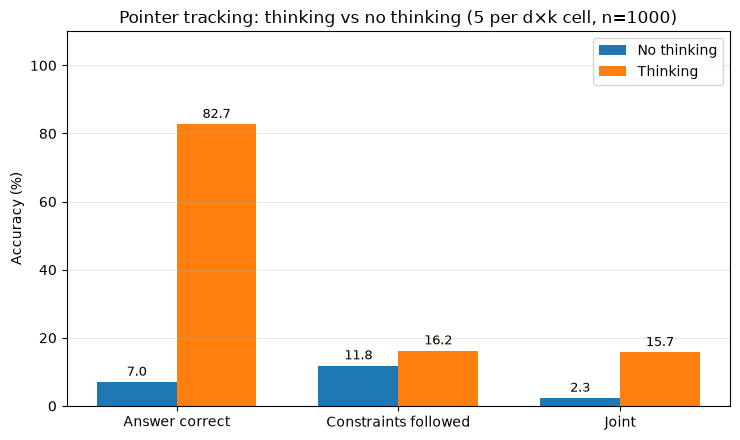

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = np.arange(len(METRICS))
width = 0.36
for offset, mode in zip([-width / 2, width / 2], MODE_ORDER):
    values = summary.loc[mode, METRICS].to_numpy() * 100
    bars = ax.bar(x + offset, values, width, label=mode)
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1.0,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )
ax.set_xticks(x)
ax.set_xticklabels(METRIC_LABELS)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 110)
ax.set_title(f"Pointer tracking: thinking vs no thinking (5 per d×k cell, n={len(pilot_rows)})")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


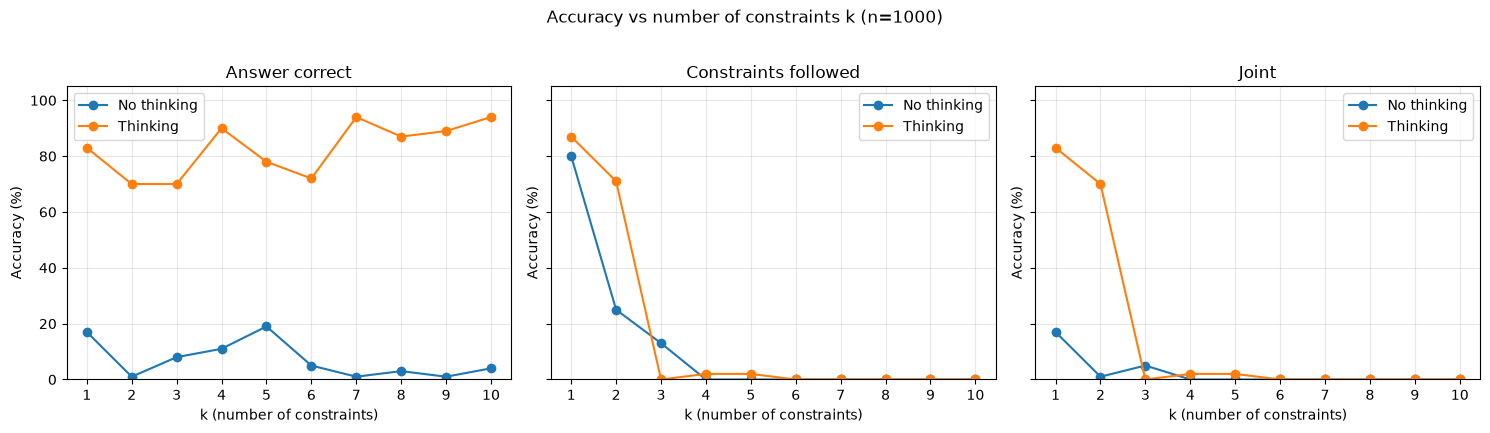

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, metric, label in zip(axes, METRICS, METRIC_LABELS):
    for mode in MODE_ORDER:
        series = df[df["mode"] == mode].groupby("k")[metric].mean() * 100
        ax.plot(series.index, series.values, marker="o", label=mode)
    ax.set_title(label)
    ax.set_xlabel("k (number of constraints)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle(f"Accuracy vs number of constraints k (n={len(pilot_rows)})", y=1.02)
plt.tight_layout()
plt.show()


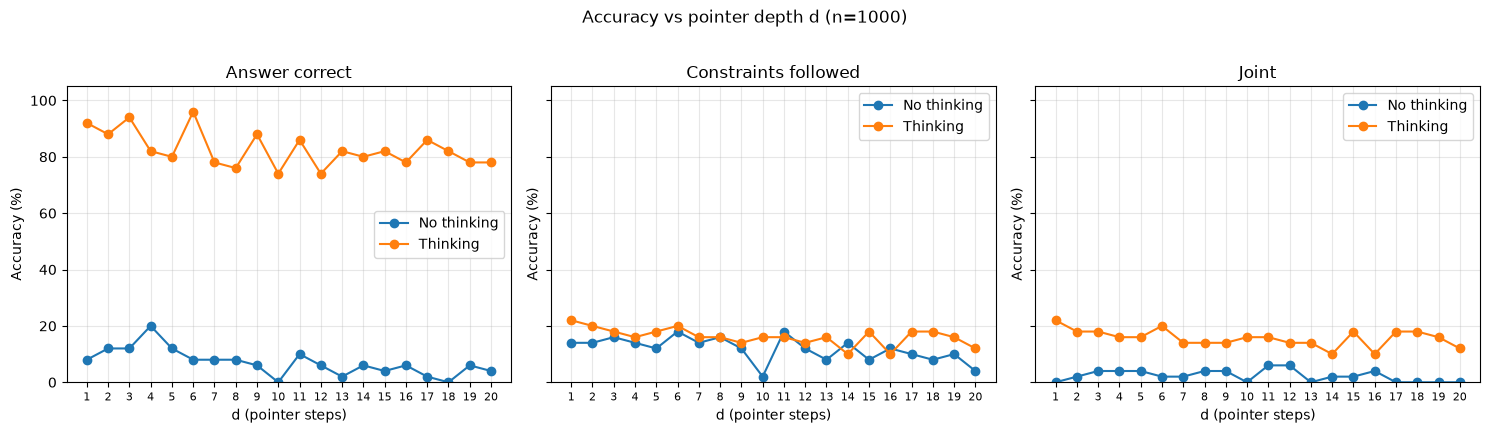

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, metric, label in zip(axes, METRICS, METRIC_LABELS):
    for mode in MODE_ORDER:
        series = df[df["mode"] == mode].groupby("d")[metric].mean() * 100
        ax.plot(series.index, series.values, marker="o", label=mode)
    ax.set_title(label)
    ax.set_xlabel("d (pointer steps)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(range(1, 21))
    ax.tick_params(axis="x", labelsize=8)
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle(f"Accuracy vs pointer depth d (n={len(pilot_rows)})", y=1.02)
plt.tight_layout()
plt.show()


=== per-constraint adherence (%) ===
mode        No thinking  Thinking
constraint                       
1                 28.10     73.50
2                 12.33     36.22
3                 39.12     35.00
4                 21.57     72.43
5                 29.33     19.17
6                100.00     97.40
7                 36.25     48.75
8                 18.67     60.33
9                  0.00      3.00
10                 0.00      2.00

=== denominator n ===
mode        No thinking  Thinking
constraint                       
1                  1000      1000
2                   900       900
3                   800       800
4                   700       700
5                   600       600
6                   500       500
7                   400       400
8                   300       300
9                   200       200
10                  100       100


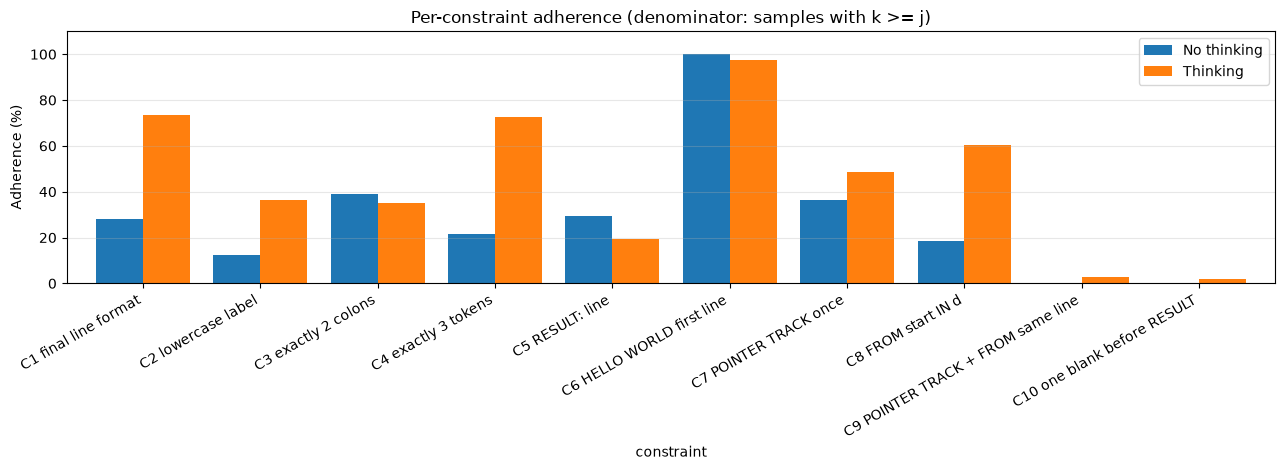

In [17]:
constraint_rows = []
for j in range(1, 11):
    sub = df[df["k"] >= j]
    for mode in MODE_ORDER:
        mode_sub = sub[sub["mode"] == mode]
        constraint_rows.append({
            "constraint": j,
            "mode": mode,
            "rate": mode_sub[f"c{j}"].mean() * 100,
            "n": len(mode_sub),
        })
constraint_df = pd.DataFrame(constraint_rows)
pivot = constraint_df.pivot(index="constraint", columns="mode", values="rate").reindex(columns=MODE_ORDER)
print("=== per-constraint adherence (%) ===")
print(pivot.round(2).to_string())
print("\n=== denominator n ===")
print(constraint_df.pivot(index="constraint", columns="mode", values="n").to_string())

fig, ax = plt.subplots(figsize=(13, 4.8))
pivot.plot(kind="bar", ax=ax, width=0.8)
ax.set_xticklabels(CONSTRAINT_NAMES, rotation=30, ha="right")
ax.set_ylabel("Adherence (%)")
ax.set_ylim(0, 110)
ax.set_title("Per-constraint adherence (denominator: samples with k >= j)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="")
plt.tight_layout()
plt.show()


In [18]:
print("=== answer wrong (first 3, thinking) ===")
for _, rec in df[(df["mode"] == "Thinking") & (~df["answer_correct"])].head(3).iterrows():
    print("-" * 80)
    print(f"d={rec['d']} k={rec['k']} i={rec['i']} ans={rec['ans']} finish={rec['finish_reason']} ntok={rec['n_tokens']}")
    print("answer_text:", repr(rec["answer_text"][:600]))
    print("thinking_text (tail):", repr(rec["thinking_text"][-400:]))

print("\n=== answer correct but constraints fail (first 3, thinking) ===")
mask = (df["mode"] == "Thinking") & df["answer_correct"] & (~df["constraint_all"])
for _, rec in df[mask].head(3).iterrows():
    print("-" * 80)
    print(f"d={rec['d']} k={rec['k']} i={rec['i']} ans={rec['ans']}")
    failed = [i for i in range(1, int(rec["k"]) + 1) if not bool(rec[f"c{i}"])]
    print("failed:", failed)
    print("answer_text:", repr(rec["answer_text"][:600]))

print("\n=== C3 failures at k=3/4 (first 3, thinking) ===")
c3_mask = (df["mode"] == "Thinking") & df["k"].isin([3, 4]) & (~df["c3"].astype(bool))
for _, rec in df[c3_mask].head(3).iterrows():
    print("-" * 80)
    print(f"d={rec['d']} k={rec['k']} i={rec['i']} ans={rec['ans']} colon_count={rec['colon_count']}")
    print("answer_text:", repr(rec["answer_text"][:600]))


=== answer wrong (first 3, thinking) ===
--------------------------------------------------------------------------------
d=1 k=4 i=3 ans=M finish=stop ntok=149
answer_text: 'Final answer: "M"'
thinking_text (tail): "the given table.\n\nThe entries are listed with their next pointers. So, each entry points to the next one. The starting point is L. Let me check the pointer for L. According to the table, L -> M. So, from L, the next entry is M. Therefore, after one step, we end at M. The answer should be M. Let me double-check to make sure I didn't mix up any letters. Yes, L points to M. So the final answer is M.\n"
--------------------------------------------------------------------------------
d=1 k=6 i=2 ans=X finish=stop ntok=286
answer_text: 'HELLO WORLD\nRESULT:\n"Final", "answer:", "x"'
thinking_text (tail): ' miss any other pointers. Let me go through the list again:\n\nA -> C\nB -> R\nC -> H\nD -> A\nE -> G\nF -> S\nG -> D\nH -> J\nJ -> V\nK -> X\nL -> N\nM -> B\nN -> S\nP -> Y\